<a href="https://colab.research.google.com/github/dhanyashrik39/air_quality_forecast/blob/main/air_quality.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Los Angeles Air Quality: Analysis and Next-Day AQI Forecasting

This notebook analyzes seven years (2019-2025) of daily air quality
data for the Los Angeles area, combined with weather data, to understand what drives
pollution and to forecast next-day AQI. It covers data cleaning, exploratory analysis,
a statistical test of the January 2025 wildfire impact, and a comparison of
Random Forest and XGBoost models against a "yesterday's AQI" baseline, with
error analysis of where the models fail.

**Data:** EPA AirData (daily AQI by CBSA) and Open-Meteo historical weather.

**Tools & Libraries:** Python, Pandas, NumPy, SciPy, scikit-learn, XGBoost, Matplotlib, Seaborn, Plotly.

In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [3]:

import pandas as pd, numpy as np, requests
import matplotlib.pyplot as plt, seaborn as sns
import plotly.express as px
from scipy.stats import mannwhitneyu

Load the EPA air quality data


In [4]:
frames = []
for y in range(2019, 2026):
    url = f"https://aqs.epa.gov/aqsweb/airdata/daily_aqi_by_cbsa_{y}.zip"
    try:
        frames.append(pd.read_csv(url, storage_options={"User-Agent": "Mozilla/5.0"}))
        print(y, "loaded")
    except Exception as e:
        print(y, "failed:", e)

aq = pd.concat(frames, ignore_index=True)
aq = aq[aq["CBSA"].str.contains("Los Angeles-Long Beach")].copy()
aq["date"] = pd.to_datetime(aq["Date"])
aq = (aq.rename(columns={"Defining Parameter": "main_pollutant",
                         "Number of Sites Reporting": "n_sites"})
        .set_index("date").sort_index()[["AQI", "main_pollutant", "n_sites"]])
print(aq.shape); aq.head()

2019 loaded
2020 loaded
2021 loaded
2022 loaded
2023 loaded
2024 loaded
2025 loaded
(2557, 3)


,AQI,main_pollutant,n_sites
date,,,
2019-01-01,71,PM2.5,20
2019-01-02,93,PM2.5,20
2019-01-03,71,PM2.5,20
2019-01-04,87,PM2.5,20
2019-01-05,85,PM2.5,20


Load weather and merge

In [5]:
params = {"latitude": 34.05, "longitude": -118.24,
          "start_date": "2019-01-01", "end_date": "2025-12-31",
          "daily": "temperature_2m_mean,relative_humidity_2m_mean,"
                   "precipitation_sum,wind_speed_10m_max",
          "timezone": "America/Los_Angeles"}
w = requests.get("https://archive-api.open-meteo.com/v1/archive", params=params).json()["daily"]
weather = pd.DataFrame(w).rename(columns={
    "time": "date", "temperature_2m_mean": "temp",
    "relative_humidity_2m_mean": "humidity",
    "precipitation_sum": "rain", "wind_speed_10m_max": "wind"})
weather["date"] = pd.to_datetime(weather["date"])
weather = weather.set_index("date")

df = aq.join(weather, how="inner")

Data quality check

In [6]:
full = pd.date_range(df.index.min(), df.index.max())
print("Missing days:", len(full.difference(df.index)))
print(df.isna().mean())
print(df.describe())

Missing days: 0
AQI               0.0
main_pollutant    0.0
n_sites           0.0
temp              0.0
humidity          0.0
rain              0.0
wind              0.0
dtype: float64
               AQI      n_sites         temp     humidity         rain  \
count  2557.000000  2557.000000  2557.000000  2557.000000  2557.000000   
mean     88.993743    18.565506    17.776183    63.887759     1.414783   
std      39.374799     1.726199     4.731024    16.665526     6.616232   
min      31.000000    15.000000     6.600000     9.000000     0.000000   
25%      60.000000    17.000000    13.900000    57.000000     0.000000   
50%      76.000000    19.000000    17.700000    68.000000     0.000000   
75%     108.000000    20.000000    21.500000    75.000000     0.000000   
max     281.000000    23.000000    34.700000    96.000000    91.900000   

              wind  
count  2557.000000  
mean     16.460540  
std       5.170352  
min       3.400000  
25%      12.900000  
50%      16.800000  
7

Data Cleaning

In [7]:
df = df.reindex(full)
df.index.name = "date"
df["main_pollutant"] = df["main_pollutant"].ffill(limit=3)
num = ["AQI", "n_sites", "temp", "humidity", "rain", "wind"]
df[num] = df[num].interpolate(method="time", limit=3)
df = df.dropna(subset=["AQI"])

Saving the cleaned dataset so no need redo Steps 1 to 4 every session

In [11]:
import os
folder = "/content/drive/MyDrive/la-aqi"
os.makedirs(folder, exist_ok=True)          # creates the folder if missing
df.to_csv(f"{folder}/la_aqi_clean.csv")
print(os.listdir(folder))                   # should show la_aqi_clean.csv

['la_aqi_clean.csv']


In [12]:

df = pd.read_csv("/content/drive/MyDrive/la-aqi/la_aqi_clean.csv", index_col="date", parse_dates=True)

Feature engineering

In [13]:
df["month"] = df.index.month
df["dayofweek"] = df.index.dayofweek
for lag in [1, 2, 7]:
    df[f"aqi_lag{lag}"] = df["AQI"].shift(lag)
df["aqi_roll7"] = df["AQI"].rolling(7).mean()
df["wind_lag1"] = df["wind"].shift(1)
df = df.join(pd.get_dummies(df["main_pollutant"], prefix="main").astype(int))
df = df.drop(columns=["main_pollutant"])
df["target"] = df["AQI"].shift(-1)      # next-day AQI
df = df.dropna()

EDA

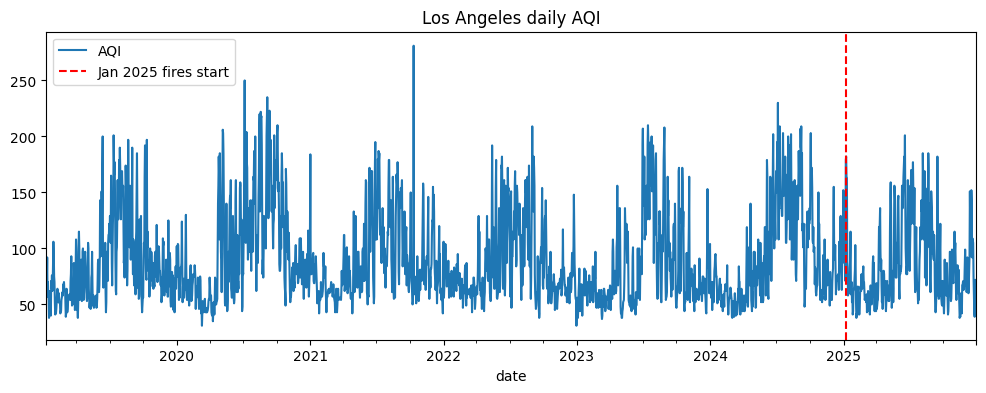

In [15]:
# 1. Timeline
ax = df["AQI"].plot(figsize=(12, 4), title="Los Angeles daily AQI")
ax.axvline("2025-01-07", color="red", ls="--", label="Jan 2025 fires start")
ax.legend(); plt.show()



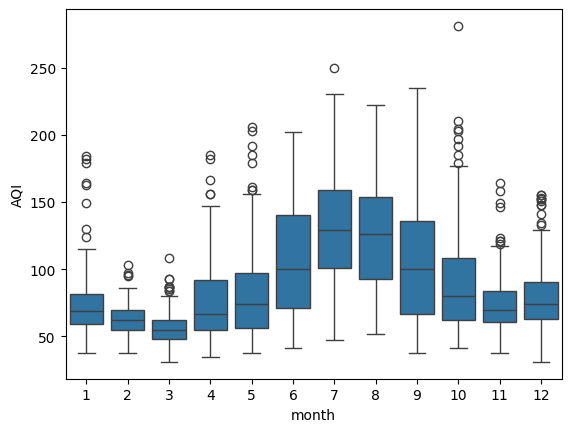

In [16]:
# 2. Seasonality
sns.boxplot(x="month", y="AQI", data=df.reset_index()); plt.show()



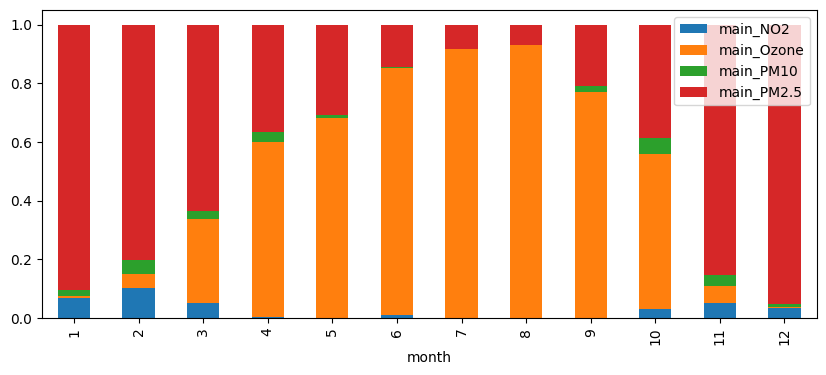

In [17]:
# 3. Which pollutant drives AQI, by month
main_cols = [c for c in df.columns if c.startswith("main_")]
df.groupby("month")[main_cols].mean().plot(kind="bar", stacked=True, figsize=(10, 4)); plt.show()



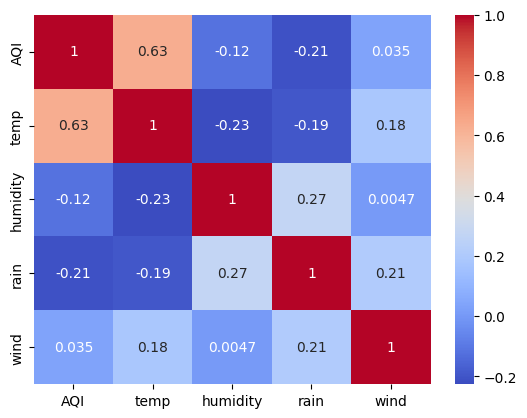

In [18]:
# 4. Correlations
sns.heatmap(df[["AQI", "temp", "humidity", "rain", "wind"]].corr(), annot=True, cmap="coolwarm"); plt.show()



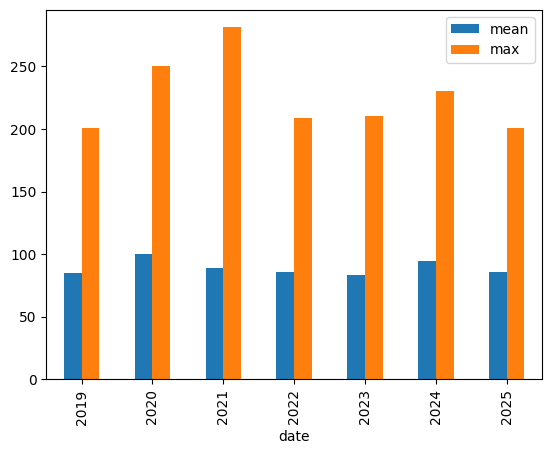

In [19]:
# 5. Yearly trend
df.groupby(df.index.year)["AQI"].agg(["mean", "max"]).plot(kind="bar"); plt.show()

Statistical test

In [20]:
jan25 = df.loc["2025-01-07":"2025-01-31", "AQI"]
prev = df[(df.index.month == 1) & (df.index.year < 2025)]["AQI"]
stat, p = mannwhitneyu(jan25, prev)
print(f"Jan 2025 (post-fire) mean: {jan25.mean():.0f} vs prior Januaries: {prev.mean():.0f}, p={p:.4f}")

Jan 2025 (post-fire) mean: 85 vs prior Januaries: 71, p=0.5836


Model Training

Baseline (yesterday): RMSE=24.3  MAE=17.6
Random Forest: RMSE=22.8  MAE=17.0
XGBoost: RMSE=23.6  MAE=17.1


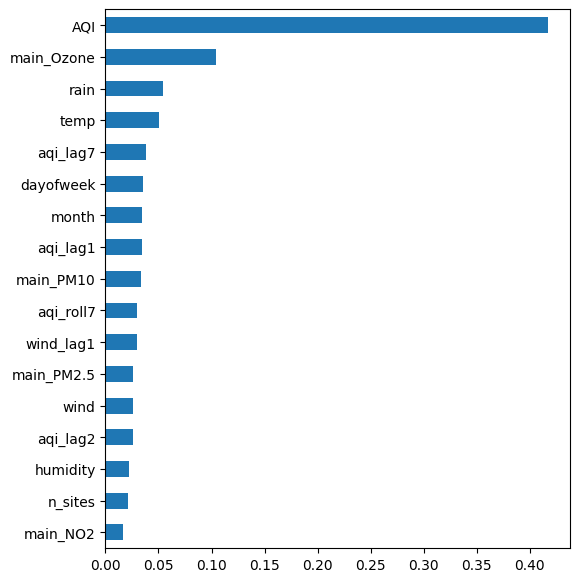

In [21]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_squared_error, mean_absolute_error
from xgboost import XGBRegressor

X, y = df.drop(columns=["target"]), df["target"]
train, test = X.index < "2024-01-01", X.index >= "2024-01-01"
Xtr, Xte, ytr, yte = X[train], X[test], y[train], y[test]

def report(name, pred):
    rmse = np.sqrt(mean_squared_error(yte, pred))
    print(f"{name}: RMSE={rmse:.1f}  MAE={mean_absolute_error(yte, pred):.1f}")

report("Baseline (yesterday)", Xte["AQI"])
rf = RandomForestRegressor(300, random_state=42, n_jobs=-1).fit(Xtr, ytr)
report("Random Forest", rf.predict(Xte))
xgb = XGBRegressor(n_estimators=400, learning_rate=0.05, max_depth=4).fit(Xtr, ytr)
report("XGBoost", xgb.predict(Xte))

pd.Series(xgb.feature_importances_, X.columns).sort_values().plot(kind="barh", figsize=(6, 7))
plt.show()

Error analysis

In [22]:
res = pd.DataFrame({"actual": yte, "pred": xgb.predict(Xte)})
res["error"] = (res["actual"] - res["pred"]).abs()
print(res.sort_values("error", ascending=False).head(10))
px.line(res[["actual", "pred"]], title="Next-day AQI: actual vs predicted").show()

            actual        pred       error
date                                      
2025-01-06   179.0   65.746437  113.253563
2024-07-07   187.0   93.979218   93.020782
2024-09-09   116.0  207.077438   91.077438
2024-06-13   164.0   79.173668   84.826332
2025-09-14   182.0   97.456436   84.543564
2025-05-11    64.0  143.800446   79.800446
2024-08-01   200.0  121.940636   78.059364
2025-01-07   182.0  107.094170   74.905830
2025-08-11    74.0  148.477707   74.477707
2024-12-30   152.0   77.917458   74.082542


In [25]:
res["base_pred"] = Xte["AQI"]                      # yesterday's AQI
res["base_error"] = (res["actual"] - res["base_pred"]).abs()
print("Model MAE:   ", res["error"].mean().round(1))
print("Baseline MAE:", res["base_error"].mean().round(1))
print("Days with error < 20:", (res["error"] < 20).mean().round(2))

Model MAE:    17.1
Baseline MAE: 17.6
Days with error < 20: 0.68


Dashboard

In [24]:
px.line(df["AQI"], title="LA AQI 2019-2025").show()
px.scatter(df.reset_index(), x="wind", y="AQI", color="month", title="Wind vs AQI").show()